In [ ]:
#pip install -q python-dotenv numpy pandas scikit-learn transformers datasets torch huggingface_hub --upgrade

In [1]:
import os
import random
import numpy as np
import pandas as pd
from dotenv import load_dotenv
from pathlib import Path

from huggingface_hub import PyTorchModelHubMixin
from transformers import AutoTokenizer, AutoModel, get_linear_schedule_with_warmup
from transformers import DataCollatorWithPadding
from sklearn.model_selection import GroupShuffleSplit
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm

from sklearn.metrics import precision_recall_fscore_support, confusion_matrix, classification_report

import time
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    average_precision_score,
    roc_auc_score,
    precision_recall_curve,
    roc_curve,
    precision_recall_fscore_support,
    confusion_matrix,
    classification_report,
)

load_dotenv()
HF_READ_TOKEN = os.getenv("HF_READ_TOKEN")
HF_WRITE_TOKEN = os.getenv("HF_WRITE_TOKEN")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", DEVICE)

Using device: cuda


In [2]:
# Encoder model
MODEL_NAME = "answerdotai/ModernBERT-base"

# Model params
MAX_LENGTH = 6000
BATCH_SIZE = 1
GRAD_ACCUM_STEPS = 8
EPOCHS = 10
LR = 2e-5
HEAD_HIDDEN = 384
DROPOUT_P = 0.2
WARMUP_RATIO = 0.06

EARLY_STOPPING_PATIENCE = 2
MIN_DELTA = 0.001

# headers: id,assignment_context,previous_conversation,user_query,assistant_response, irrelevancy,solution_proximality
TRAIN_VAL_DIR = "../lab_exercise_dataset"
TEST_DIR = "../golden_dataset"
VAL_SIZE = 0.2
LABEL_COL = "solution_proximality"  # 1 = direct solution, 0 = general guidance

OUTPUT_DIR = "../solution_proximality_modernbert"
BEST_CHECKPOINT_PATH = os.path.join(OUTPUT_DIR, "best.pt")
LAST_CHECKPOINT_PATH = os.path.join(OUTPUT_DIR, "last.pt")
os.makedirs(OUTPUT_DIR, exist_ok=True)

HISTORY_PATH = os.path.join(OUTPUT_DIR, "training_history.csv")
FIGURE_DIR = os.path.join(OUTPUT_DIR, "figures")
os.makedirs(FIGURE_DIR, exist_ok=True)

HF_REPO_ID = os.getenv("HF_SOLUTION_PROXIMALITY_REPO_ID")
if not HF_READ_TOKEN or not HF_WRITE_TOKEN or not HF_REPO_ID:
    raise ValueError("Set HF_READ_TOKEN, HF_WRITE_TOKEN, and HF_SOLUTION_PROXIMALITY_REPO_ID in your environment before training.")

In [3]:
from pathlib import Path
import pandas as pd

files = sorted(Path(TRAIN_VAL_DIR).glob("*.csv"))

df = pd.read_csv(files[0])

print(files[0].name)
print(
    df.tail(4)[
        ["solution_proximality", "user_query", "assistant_response"]
    ]
)

bacse102_0_1_knapsack_using_dynamic_programming_scored.csv
   solution_proximality                                         user_query  \
7                   yes  // TODO: Handle invalid input cases give the b...   
8                   yes  Can you give me a complete worked implementati...   
9                   yes  Please give the complete solution for 0/1 Knap...   
10                   no  What does the item-count dimension mean in the...   

                                   assistant_response  
7   ```java\r\n// Basic structure for input valida...  
8   Here is the complete dynamic-programming proce...  
9   Use a zero-filled table best[n+1][capacity+1]....  
10  It identifies which prefix of the items is ava...  


In [4]:
from pathlib import Path
import pandas as pd

def load_folder(path, mark_synthetic=False):
    files = sorted(Path(path).glob("*.csv"))
    frames = []

    for i, file in enumerate(files):
        df = pd.read_csv(file)

        if mark_synthetic:
            if i < 80:
                # Tail structure:
                # -3 = old synthetic positive
                # -2 = new synthetic positive
                # -1 = new synthetic negative
                if len(df) < 3:
                    raise ValueError(f"{file.name}: expected at least 3 rows")

                df = df.drop(df.index[-3]).reset_index(drop=True)

                df["is_synthetic"] = False
                df.loc[df.index[-2:], "is_synthetic"] = True

            else:
                # Remaining files contain only the old positive augmentation
                # as their final row. Remove it completely.
                if len(df) < 1:
                    raise ValueError(f"{file.name}: empty CSV")

                df = df.drop(df.index[-1]).reset_index(drop=True)
                df["is_synthetic"] = False

        else:
            # Test / non-augmented corpus
            df["is_synthetic"] = False

        df["source_file"] = file.name
        frames.append(df)

    return pd.concat(frames, ignore_index=True)
    


train_val_df = load_folder(TRAIN_VAL_DIR, mark_synthetic=True)
test_df = load_folder(TEST_DIR)
print("Total rows:", len(train_val_df))
print("Synthetic rows:", train_val_df["is_synthetic"].sum())
print("Real rows:", (~train_val_df["is_synthetic"]).sum())

print("\nSynthetic label distribution:")
print(
    train_val_df.loc[
        train_val_df["is_synthetic"],
        LABEL_COL
    ].value_counts()
)

# train_df.head()

Total rows: 1008
Synthetic rows: 160
Real rows: 848

Synthetic label distribution:
solution_proximality
yes    80
no     80
Name: count, dtype: int64


In [5]:
splitter = GroupShuffleSplit(n_splits=1, test_size=VAL_SIZE, random_state=SEED)

train_idx, val_idx = next(
    splitter.split(
        train_val_df,
        groups=train_val_df["assignment_id"]
    )
)

train_df = train_val_df.iloc[train_idx].reset_index(drop=True)
val_df = train_val_df.iloc[val_idx].reset_index(drop=True)
val_df = val_df[
    ~val_df["is_synthetic"]
].reset_index(drop=True)

train_assignments = set(train_df["assignment_id"])
val_assignments = set(val_df["assignment_id"])
test_assignments = set(test_df["assignment_id"])

assert train_assignments.isdisjoint(val_assignments)

print("Train:", train_df.shape, "| assignments:", len(train_assignments))
print("Val:", val_df.shape, "| assignments:", len(val_assignments))
print("Test:", test_df.shape, "| assignments:", len(test_assignments))

assert len(train_val_df) == 1008
assert train_val_df["is_synthetic"].sum() == 160
assert (~train_val_df["is_synthetic"]).sum() == 848

synthetic_counts = (
    train_val_df.loc[
        train_val_df["is_synthetic"],
        LABEL_COL
    ]
    .str.lower()
    .value_counts()
)

assert synthetic_counts["yes"] == 80
assert synthetic_counts["no"] == 80
assert test_df["is_synthetic"].sum() == 0

Train: (800, 14) | assignments: 121
Val: (176, 14) | assignments: 31
Test: (46, 14) | assignments: 8


In [6]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME, token=HF_READ_TOKEN)

def check_lengths(df):
    lengths = []

    for _, row in df.iterrows():
        text = (
            f"[ASSIGNMENT]\n{str(row['assignment_context']).strip()}\n\n"
            f"[PREVIOUS CONVERSATION]\n{str(row['previous_conversation']).strip()}\n\n"
            f"[CURRENT USER QUERY]\n{str(row['user_query']).strip()}\n\n"
            f"[CURRENT ASSISTANT RESPONSE]\n{str(row['assistant_response']).strip()}"
        )

        lengths.append(len(tokenizer(text, add_special_tokens=True)["input_ids"]))

    lengths = np.array(lengths)

    print("Median:", np.median(lengths))
    print("95th percentile:", np.percentile(lengths, 95))
    print("Maximum:", lengths.max())
    print("Over 4096:", np.sum(lengths > MAX_LENGTH), "/", len(lengths))



check_lengths(train_df)
check_lengths(val_df)

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (11208 > 8192). Running this sequence through the model will result in indexing errors


Median: 789.0
95th percentile: 2646.949999999999
Maximum: 11208
Over 4096: 10 / 800
Median: 719.5
95th percentile: 1773.75
Maximum: 5296
Over 4096: 0 / 176


In [7]:
print("\nTrain labels:")
print(train_df[LABEL_COL].value_counts())

print("\nSynthetic train rows:")
print(train_df["is_synthetic"].value_counts())

print("\nSynthetic train labels:")
print(
    train_df.loc[
        train_df["is_synthetic"],
        LABEL_COL
    ].value_counts()
)

print("\nValidation labels:")
print(val_df[LABEL_COL].value_counts())

print("\nValidation synthetic rows:")
print(val_df["is_synthetic"].sum())


Train labels:
solution_proximality
no     715
yes     85
Name: count, dtype: int64

Synthetic train rows:
is_synthetic
False    672
True     128
Name: count, dtype: int64

Synthetic train labels:
solution_proximality
yes    64
no     64
Name: count, dtype: int64

Validation labels:
solution_proximality
no     170
yes      6
Name: count, dtype: int64

Validation synthetic rows:
0


In [8]:
data_collator = DataCollatorWithPadding(
    tokenizer=tokenizer,
    padding=True,
    return_tensors="pt",
)


class ProximalityDataset(Dataset):
    def __init__(self, df, tokenizer, max_length=MAX_LENGTH):
        self.df = df.reset_index(drop=True)
        self.tokenizer = tokenizer
        self.max_length = max_length

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]

        assignment = str(row["assignment_context"]).strip()
        previous = str(row["previous_conversation"]).strip()
        query = str(row["user_query"]).strip()
        response = str(row["assistant_response"]).strip()

        text = (
            f"[ASSIGNMENT]\n{assignment}\n\n"
            f"[PREVIOUS CONVERSATION]\n{previous}\n\n"
            f"[CURRENT USER QUERY]\n{query}\n\n"
            f"[CURRENT ASSISTANT RESPONSE]\n{response}"
        )

        enc = self.tokenizer(
            text,
            truncation=True,
            max_length=self.max_length,
        )

        item = {
            "input_ids": enc["input_ids"],
            "attention_mask": enc["attention_mask"],
            "label": 1 if str(row[LABEL_COL]).strip().lower() == "yes" else 0,
        }

        return item


train_ds = ProximalityDataset(train_df, tokenizer)
val_ds = ProximalityDataset(val_df, tokenizer)

train_loader = DataLoader(
    train_ds,
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=data_collator
)

val_loader = DataLoader(
    val_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=data_collator
)

In [9]:
class ProximalityClassifier(nn.Module, PyTorchModelHubMixin):
    def __init__(self, model_name=MODEL_NAME, 
                 hidden_size=768,  # 1024 for ModernBERT-large
                 head_hidden=HEAD_HIDDEN,
                 dropout_p=DROPOUT_P, 
                 num_labels=2):
        super().__init__()
        self.encoder = AutoModel.from_pretrained(model_name, token=HF_READ_TOKEN)
        self.head = nn.Sequential(
            nn.Linear(hidden_size, head_hidden),
            nn.GELU(),
            nn.Dropout(dropout_p),
            nn.Linear(head_hidden, num_labels),
        )

    def forward(self, input_ids, attention_mask):
        outputs = self.encoder(input_ids=input_ids, attention_mask=attention_mask)
        cls_repr = outputs.last_hidden_state[:, 0, :]   # [CLS] pooling
        logits = self.head(cls_repr)
        return logits

model = ProximalityClassifier().to(DEVICE)
print(model)

Loading weights:   0%|          | 0/134 [00:00<?, ?it/s]

[transformers] ModernBertModel LOAD REPORT from: answerdotai/ModernBERT-base
Key               | Status     |  | 
------------------+------------+--+-
decoder.bias      | UNEXPECTED |  | 
head.dense.weight | UNEXPECTED |  | 
head.norm.weight  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


ProximalityClassifier(
  (encoder): ModernBertModel(
    (embeddings): ModernBertEmbeddings(
      (tok_embeddings): Embedding(50368, 768, padding_idx=50283)
      (norm): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=False)
      (drop): Dropout(p=0.0, inplace=False)
    )
    (layers): ModuleList(
      (0): ModernBertEncoderLayer(
        (attn_norm): Identity()
        (attn): ModernBertAttention(
          (Wqkv): Linear(in_features=768, out_features=2304, bias=False)
          (Wo): Linear(in_features=768, out_features=768, bias=False)
          (out_drop): Identity()
        )
        (mlp_norm): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=False)
        (mlp): ModernBertMLP(
          (Wi): Linear(in_features=768, out_features=2304, bias=False)
          (act): GELUActivation()
          (drop): Dropout(p=0.0, inplace=False)
          (Wo): Linear(in_features=1152, out_features=768, bias=False)
        )
      )
      (1-21): 21 x ModernBertEncoderLa

In [10]:
label_counts = train_df[LABEL_COL].str.lower().value_counts()
print("Label counts (train):\n", label_counts)

n_total = label_counts.sum()
n_classes = 2

counts_by_id = {
    0: label_counts.get("no", 0),   # general guidance
    1: label_counts.get("yes", 0),  # direct answer
}

class_weights = torch.tensor(
    [n_total / (n_classes * max(counts_by_id[c], 1)) for c in range(n_classes)],
    dtype=torch.float,
).to(DEVICE)
print("Class weights:", class_weights)

criterion = nn.CrossEntropyLoss(weight=class_weights, reduction="none")

Label counts (train):
 solution_proximality
no     715
yes     85
Name: count, dtype: int64
Class weights: tensor([0.5594, 4.7059], device='cuda:0')


In [11]:
# Training Hyperparams
optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=0.01)
steps_per_epoch = (len(train_loader) + GRAD_ACCUM_STEPS - 1) // GRAD_ACCUM_STEPS
total_steps = steps_per_epoch * EPOCHS
warmup_steps = int(WARMUP_RATIO * total_steps)

scheduler = get_linear_schedule_with_warmup(
    optimizer,
    num_warmup_steps=warmup_steps,
    num_training_steps=total_steps
)


def run_epoch(loader, train_mode=True):
    model.train() if train_mode else model.eval()

    total_loss = 0.0
    total_tokens = 0
    all_preds, all_labels, all_probs = [], [], []

    context = torch.enable_grad() if train_mode else torch.no_grad()

    if DEVICE.type == "cuda":
        torch.cuda.synchronize()
        torch.cuda.reset_peak_memory_stats()

    start_time = time.perf_counter()

    if train_mode:
        optimizer.zero_grad()

    with context:
        progress = tqdm(
            loader,
            desc="Training" if train_mode else "Validation",
            leave=False
        )

        for batch_idx, batch in enumerate(progress):
            input_ids = batch["input_ids"].to(DEVICE)
            attention_mask = batch["attention_mask"].to(DEVICE)
            labels = batch["labels"].to(DEVICE)

            total_tokens += int(attention_mask.sum().item())

            logits = model(input_ids, attention_mask)
            loss = criterion(logits, labels).mean()

            if train_mode:
                scaled_loss = loss / GRAD_ACCUM_STEPS
                scaled_loss.backward()

                should_step = (
                    (batch_idx + 1) % GRAD_ACCUM_STEPS == 0
                    or (batch_idx + 1) == len(loader)
                )

                if should_step:
                    torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
                    optimizer.step()
                    scheduler.step()
                    optimizer.zero_grad()

            total_loss += loss.item() * input_ids.size(0)

            probs = torch.softmax(logits, dim=-1)[:, 1]
            preds = torch.argmax(logits, dim=-1)

            all_probs.extend(probs.detach().cpu().tolist())
            all_preds.extend(preds.detach().cpu().tolist())
            all_labels.extend(labels.detach().cpu().tolist())

            progress.set_postfix(loss=f"{loss.item():.4f}")

    if DEVICE.type == "cuda":
        torch.cuda.synchronize()

    elapsed = time.perf_counter() - start_time
    avg_loss = total_loss / len(loader.dataset)

    macro_precision, macro_recall, macro_f1, _ = precision_recall_fscore_support(
        all_labels, all_preds, average="macro", zero_division=0
    )

    pos_precision, pos_recall, pos_f1, _ = precision_recall_fscore_support(
        all_labels, all_preds, average="binary", zero_division=0
    )

    accuracy = accuracy_score(all_labels, all_preds)
    balanced_accuracy = balanced_accuracy_score(all_labels, all_preds)

    roc_auc = (
        roc_auc_score(all_labels, all_probs)
        if len(set(all_labels)) == 2 else float("nan")
    )

    pr_auc = (
        average_precision_score(all_labels, all_probs)
        if len(set(all_labels)) == 2 else float("nan")
    )

    tn, fp, fn, tp = confusion_matrix(
        all_labels,
        all_preds,
        labels=[0, 1]
    ).ravel()

    fpr = fp / (fp + tn) if fp + tn else float("nan")

    stats = {
        "accuracy": accuracy,
        "balanced_accuracy": balanced_accuracy,

        "macro_precision": macro_precision,
        "macro_recall": macro_recall,
        "macro_f1": macro_f1,

        "positive_precision": pos_precision,
        "positive_recall": pos_recall,
        "positive_f1": pos_f1,

        "roc_auc": roc_auc,
        "pr_auc": pr_auc,
        "fpr": fpr,

        "predicted_positives": int(sum(all_preds)),

        "seconds": elapsed,
        "samples_per_second": len(loader.dataset) / elapsed,
        "tokens_per_second": total_tokens / elapsed,

        "peak_allocated_vram_gib": (
            torch.cuda.max_memory_allocated() / 1024**3
            if DEVICE.type == "cuda" else float("nan")
        ),

        "peak_reserved_vram_gib": (
            torch.cuda.max_memory_reserved() / 1024**3
            if DEVICE.type == "cuda" else float("nan")
        ),
    }

    return avg_loss, all_preds, all_labels, all_probs, stats
    model.train() if train_mode else model.eval()
    total_loss = 0.0
    all_preds, all_labels = [], []

    context = torch.enable_grad() if train_mode else torch.no_grad()

    if train_mode:
        optimizer.zero_grad()

    with context:
        progress = tqdm(
            loader,
            desc="Training" if train_mode else "Validation",
            leave=False
        )

        for batch_idx, batch in enumerate(progress):
            input_ids = batch["input_ids"].to(DEVICE)
            attention_mask = batch["attention_mask"].to(DEVICE)
            labels = batch["labels"].to(DEVICE)

            logits = model(input_ids, attention_mask)
            loss = criterion(logits, labels).mean()

            if train_mode:
                scaled_loss = loss / GRAD_ACCUM_STEPS
                scaled_loss.backward()
            
                should_step = (
                    (batch_idx + 1) % GRAD_ACCUM_STEPS == 0
                    or (batch_idx + 1) == len(loader)
                )
            
                if should_step:
                    torch.nn.utils.clip_grad_norm_(
                        model.parameters(),
                        max_norm=1.0
                    )
            
                    optimizer.step()
                    scheduler.step()
                    optimizer.zero_grad()

            total_loss += loss.item() * input_ids.size(0)

            preds = torch.argmax(logits, dim=-1)
            all_preds.extend(preds.cpu().tolist())
            all_labels.extend(labels.cpu().tolist())

            progress.set_postfix(loss=f"{loss.item():.4f}")

    avg_loss = total_loss / len(loader.dataset)

    precision, recall, f1, _ = precision_recall_fscore_support(
        all_labels,
        all_preds,
        average="macro",
        zero_division=0
    )

    return avg_loss, precision, recall, f1, all_preds, all_labels


# Training Loop
best_val_pr_auc = -1.0
epochs_without_improvement = 0
history = []

for epoch in range(1, EPOCHS + 1):
    print(f"\nEpoch {epoch}/{EPOCHS}")

    train_loss, train_preds, train_labels, train_probs, train_stats = run_epoch(
        train_loader,
        train_mode=True
    )

    val_loss, val_preds, val_labels, val_probs, val_stats = run_epoch(
        val_loader,
        train_mode=False
    )

    print(
        f"predicted positives: "
        f"train={train_stats['predicted_positives']}/{len(train_preds)} | "
        f"val={val_stats['predicted_positives']}/{len(val_preds)}"
    )

    print(
        f"train_loss={train_loss:.4f} "
        f"train_f1={train_stats['macro_f1']:.4f} "
        f"train_pr_auc={train_stats['pr_auc']:.4f} | "
        f"val_loss={val_loss:.4f} "
        f"val_f1={val_stats['macro_f1']:.4f} "
        f"val_pr_auc={val_stats['pr_auc']:.4f} "
        f"val_roc_auc={val_stats['roc_auc']:.4f} | "
        f"VRAM={train_stats['peak_allocated_vram_gib']:.2f} GiB "
        f"time={train_stats['seconds']:.1f}s",
        flush=True
    )

    history.append({
        "epoch": epoch,

        "train_loss": train_loss,
        "val_loss": val_loss,

        "train_macro_f1": train_stats["macro_f1"],
        "val_macro_f1": val_stats["macro_f1"],

        "train_positive_precision": train_stats["positive_precision"],
        "train_positive_recall": train_stats["positive_recall"],
        "train_positive_f1": train_stats["positive_f1"],

        "val_positive_precision": val_stats["positive_precision"],
        "val_positive_recall": val_stats["positive_recall"],
        "val_positive_f1": val_stats["positive_f1"],

        "train_pr_auc": train_stats["pr_auc"],
        "val_pr_auc": val_stats["pr_auc"],

        "train_roc_auc": train_stats["roc_auc"],
        "val_roc_auc": val_stats["roc_auc"],

        "train_fpr": train_stats["fpr"],
        "val_fpr": val_stats["fpr"],

        "train_predicted_positives": train_stats["predicted_positives"],
        "val_predicted_positives": val_stats["predicted_positives"],

        "train_seconds": train_stats["seconds"],
        "val_seconds": val_stats["seconds"],

        "train_samples_per_second": train_stats["samples_per_second"],
        "train_tokens_per_second": train_stats["tokens_per_second"],

        "train_peak_allocated_vram_gib": train_stats["peak_allocated_vram_gib"],
        "train_peak_reserved_vram_gib": train_stats["peak_reserved_vram_gib"],

        "learning_rate": optimizer.param_groups[0]["lr"],
    })

    pd.DataFrame(history).to_csv(HISTORY_PATH, index=False)

    torch.save(model.state_dict(), LAST_CHECKPOINT_PATH)

    if val_stats["pr_auc"] > best_val_pr_auc + MIN_DELTA:
        best_val_pr_auc = val_stats["pr_auc"]
        epochs_without_improvement = 0

        torch.save(model.state_dict(), BEST_CHECKPOINT_PATH)

        print(
            f"  -> new best val_pr_auc={best_val_pr_auc:.4f}, "
            f"saved to {BEST_CHECKPOINT_PATH}.",
            flush=True
        )

    else:
        epochs_without_improvement += 1

        print(
            f"  -> no significant improvement "
            f"({epochs_without_improvement}/{EARLY_STOPPING_PATIENCE})",
            flush=True
        )

        if epochs_without_improvement >= EARLY_STOPPING_PATIENCE:
            print(
                f"Early stopping triggered. "
                f"Best val_pr_auc={best_val_pr_auc:.4f}",
                flush=True
            )
            break


Epoch 1/10


Training:   0%|          | 0/800 [00:00<?, ?it/s]

Validation:   0%|          | 0/176 [00:00<?, ?it/s]

predicted positives: train=103/800 | val=0/176
train_loss=0.6880 train_f1=0.6625 train_pr_auc=0.4611 | val_loss=0.7048 val_f1=0.4913 val_pr_auc=0.3301 val_roc_auc=0.7843 | VRAM=10.39 GiB time=132.7s
  -> new best val_pr_auc=0.3301, saved to ../solution_proximality_modernbert/best.pt.

Epoch 2/10


Training:   0%|          | 0/800 [00:00<?, ?it/s]

Validation:   0%|          | 0/176 [00:00<?, ?it/s]

predicted positives: train=62/800 | val=0/176
train_loss=0.6210 train_f1=0.9139 train_pr_auc=0.8011 | val_loss=0.8345 val_f1=0.4913 val_pr_auc=0.0940 val_roc_auc=0.5549 | VRAM=10.39 GiB time=133.5s
  -> no significant improvement (1/2)

Epoch 3/10


Training:   0%|          | 0/800 [00:00<?, ?it/s]

Validation:   0%|          | 0/176 [00:00<?, ?it/s]

predicted positives: train=64/800 | val=0/176
train_loss=0.5110 train_f1=0.9223 train_pr_auc=0.8479 | val_loss=0.8273 val_f1=0.4913 val_pr_auc=0.0995 val_roc_auc=0.6725 | VRAM=10.39 GiB time=133.5s
  -> no significant improvement (2/2)
Early stopping triggered. Best val_pr_auc=0.3301


In [12]:
import numpy as np
import pandas as pd
import torch

from sklearn.metrics import (
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    average_precision_score,
    roc_auc_score,
)

model.load_state_dict(torch.load(BEST_CHECKPOINT_PATH, map_location=DEVICE))
model.eval()

val_labels = []
val_probs = []

with torch.no_grad():
    for batch in val_loader:
        input_ids = batch["input_ids"].to(DEVICE)
        attention_mask = batch["attention_mask"].to(DEVICE)
        labels = batch["labels"].to(DEVICE)

        logits = model(input_ids, attention_mask)
        probs = torch.softmax(logits, dim=-1)[:, 1]

        val_probs.extend(probs.cpu().tolist())
        val_labels.extend(labels.cpu().tolist())

print(f"ROC-AUC: {roc_auc_score(val_labels, val_probs):.4f}")
print(f"PR-AUC:  {average_precision_score(val_labels, val_probs):.4f}")

thresholds = sorted(set(val_probs))
rows = []

for threshold in thresholds:
    preds = [int(p >= threshold) for p in val_probs]

    tn, fp, fn, tp = confusion_matrix(
        val_labels,
        preds,
        labels=[0, 1]
    ).ravel()

    rows.append({
        "threshold": threshold,
        "macro_f1": f1_score(
            val_labels,
            preds,
            average="macro",
            zero_division=0
        ),
        "precision": precision_score(
            val_labels,
            preds,
            zero_division=0
        ),
        "recall": recall_score(
            val_labels,
            preds,
            zero_division=0
        ),
        "fpr": fp / (fp + tn) if fp + tn else 0.0,
        "tn": tn,
        "fp": fp,
        "fn": fn,
        "tp": tp,
    })

threshold_df = pd.DataFrame(rows)

print("\nBest thresholds by macro-F1:")
print(
    threshold_df
    .sort_values(
        ["macro_f1", "fpr"],
        ascending=[False, True]
    )
    .head(20)
    .to_string(index=False)
)

best_row = (
    threshold_df
    .sort_values(
        ["macro_f1", "fpr"],
        ascending=[False, True]
    )
    .iloc[0]
)

BEST_THRESHOLD = float(best_row["threshold"])

print(f"\nSelected threshold: {BEST_THRESHOLD:.8f}")
print(best_row.to_string())

ROC-AUC: 0.7843
PR-AUC:  0.3301

Best thresholds by macro-F1:
 threshold  macro_f1  precision   recall      fpr  tn  fp  fn  tp
  0.014606  0.691228   0.500000 0.333333 0.011765 168   2   4   2
  0.014148  0.671554   0.400000 0.333333 0.017647 167   3   4   2
  0.014049  0.654902   0.333333 0.333333 0.023529 166   4   4   2
  0.013797  0.640572   0.285714 0.333333 0.029412 165   5   4   2
  0.017446  0.635611   1.000000 0.166667 0.000000 170   0   5   1
  0.013733  0.628064   0.250000 0.333333 0.035294 164   6   4   2
  0.013666  0.617013   0.222222 0.333333 0.041176 163   7   4   2
  0.016256  0.616279   0.500000 0.166667 0.005882 169   1   5   1
  0.012946  0.612121   0.187500 0.500000 0.076471 157  13   3   3
  0.013584  0.607143   0.200000 0.333333 0.047059 162   8   4   2
  0.012748  0.604599   0.176471 0.500000 0.082353 156  14   3   3
  0.015100  0.600907   0.333333 0.166667 0.011765 168   2   5   1
  0.012368  0.599172   0.166667 0.666667 0.117647 150  20   2   4
  0.013512  0.

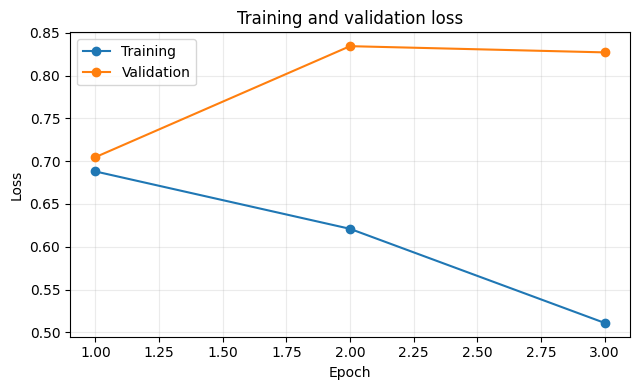

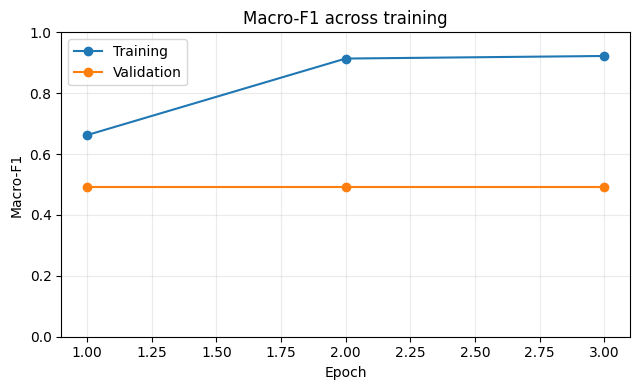

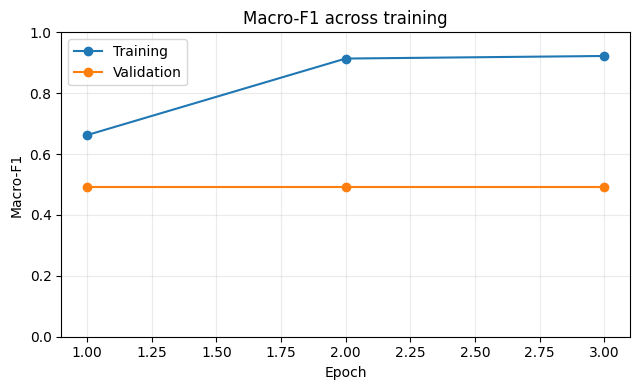

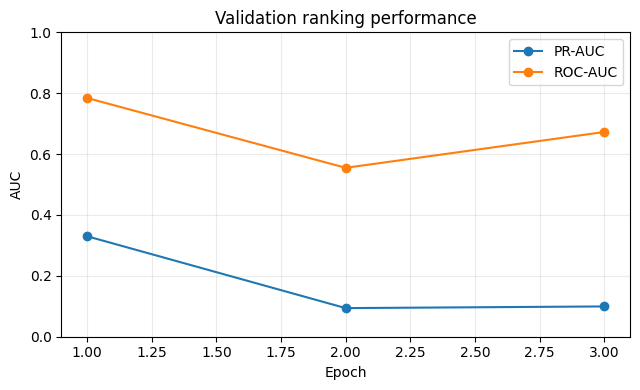

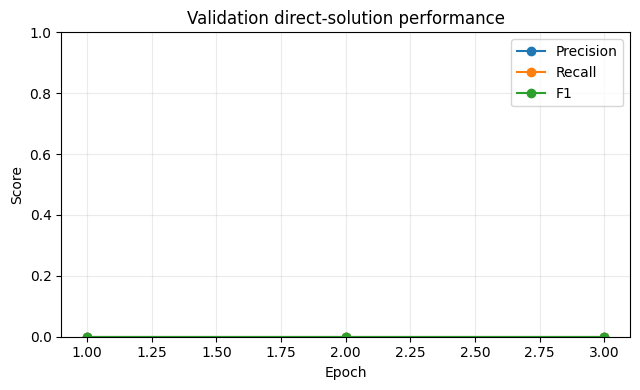

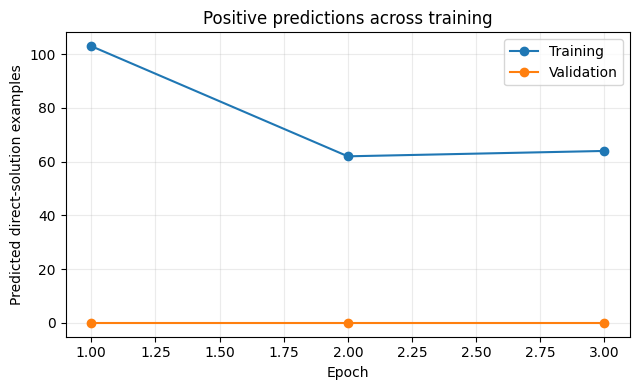

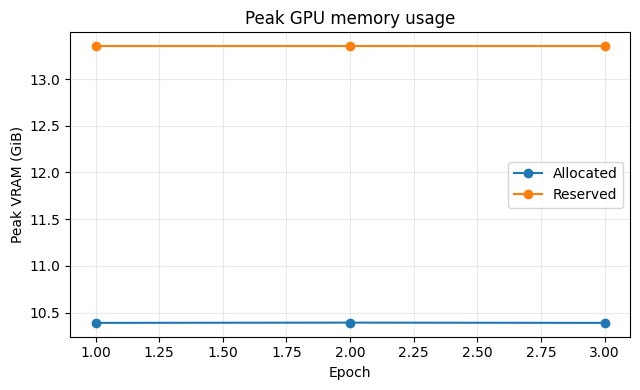

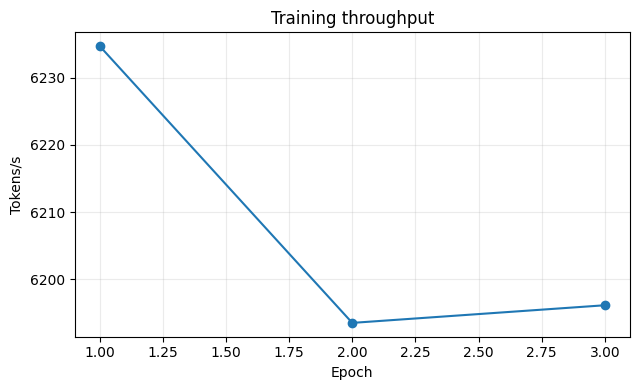

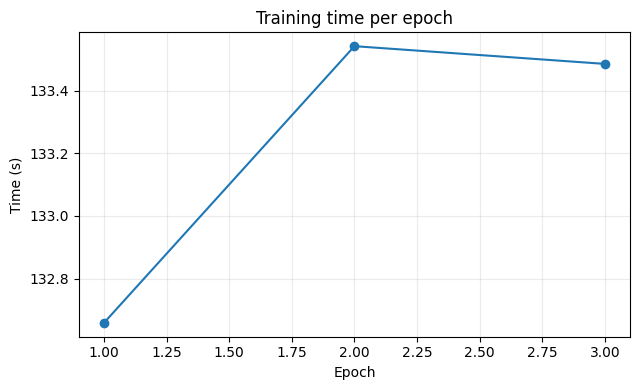

In [14]:
history_df = pd.read_csv(HISTORY_PATH)

def save_figure(fig, name):
    fig.tight_layout()
    fig.savefig(
        os.path.join(FIGURE_DIR, f"{name}.pdf"),
        bbox_inches="tight"
    )
    fig.savefig(
        os.path.join(FIGURE_DIR, f"{name}.png"),
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()

fig, ax = plt.subplots(figsize=(6.5, 4))

ax.plot(history_df["epoch"], history_df["train_loss"], marker="o", label="Training")
ax.plot(history_df["epoch"], history_df["val_loss"], marker="o", label="Validation")

ax.set_xlabel("Epoch")
ax.set_ylabel("Loss")
ax.set_title("Training and validation loss")
ax.grid(alpha=0.25)
ax.legend()

save_figure(fig, "loss_curve")


fig, ax = plt.subplots(figsize=(6.5, 4))

ax.plot(history_df["epoch"], history_df["train_macro_f1"], marker="o", label="Training")
ax.plot(history_df["epoch"], history_df["val_macro_f1"], marker="o", label="Validation")

ax.set_xlabel("Epoch")
ax.set_ylabel("Macro-F1")
ax.set_ylim(0, 1)
ax.set_title("Macro-F1 across training")
ax.grid(alpha=0.25)
ax.legend()

save_figure(fig, "macro_f1_curve")


fig, ax = plt.subplots(figsize=(6.5, 4))

ax.plot(history_df["epoch"], history_df["train_macro_f1"], marker="o", label="Training")
ax.plot(history_df["epoch"], history_df["val_macro_f1"], marker="o", label="Validation")

ax.set_xlabel("Epoch")
ax.set_ylabel("Macro-F1")
ax.set_ylim(0, 1)
ax.set_title("Macro-F1 across training")
ax.grid(alpha=0.25)
ax.legend()

save_figure(fig, "macro_f1_curve")


fig, ax = plt.subplots(figsize=(6.5, 4))

ax.plot(history_df["epoch"], history_df["val_pr_auc"], marker="o", label="PR-AUC")
ax.plot(history_df["epoch"], history_df["val_roc_auc"], marker="o", label="ROC-AUC")

ax.set_xlabel("Epoch")
ax.set_ylabel("AUC")
ax.set_ylim(0, 1)
ax.set_title("Validation ranking performance")
ax.grid(alpha=0.25)
ax.legend()

save_figure(fig, "validation_auc")


fig, ax = plt.subplots(figsize=(6.5, 4))

ax.plot(
    history_df["epoch"],
    history_df["val_positive_precision"],
    marker="o",
    label="Precision"
)

ax.plot(
    history_df["epoch"],
    history_df["val_positive_recall"],
    marker="o",
    label="Recall"
)

ax.plot(
    history_df["epoch"],
    history_df["val_positive_f1"],
    marker="o",
    label="F1"
)

ax.set_xlabel("Epoch")
ax.set_ylabel("Score")
ax.set_ylim(0, 1)
ax.set_title("Validation direct-solution performance")
ax.grid(alpha=0.25)
ax.legend()

save_figure(fig, "validation_positive_metrics")


fig, ax = plt.subplots(figsize=(6.5, 4))

ax.plot(
    history_df["epoch"],
    history_df["train_predicted_positives"],
    marker="o",
    label="Training"
)

ax.plot(
    history_df["epoch"],
    history_df["val_predicted_positives"],
    marker="o",
    label="Validation"
)

ax.set_xlabel("Epoch")
ax.set_ylabel("Predicted direct-solution examples")
ax.set_title("Positive predictions across training")
ax.grid(alpha=0.25)
ax.legend()

save_figure(fig, "predicted_positives")


fig, ax = plt.subplots(figsize=(6.5, 4))

ax.plot(
    history_df["epoch"],
    history_df["train_peak_allocated_vram_gib"],
    marker="o",
    label="Allocated"
)

ax.plot(
    history_df["epoch"],
    history_df["train_peak_reserved_vram_gib"],
    marker="o",
    label="Reserved"
)

ax.set_xlabel("Epoch")
ax.set_ylabel("Peak VRAM (GiB)")
ax.set_title("Peak GPU memory usage")
ax.grid(alpha=0.25)
ax.legend()

save_figure(fig, "training_vram")


fig, ax = plt.subplots(figsize=(6.5, 4))

ax.plot(
    history_df["epoch"],
    history_df["train_tokens_per_second"],
    marker="o"
)

ax.set_xlabel("Epoch")
ax.set_ylabel("Tokens/s")
ax.set_title("Training throughput")
ax.grid(alpha=0.25)

save_figure(fig, "training_throughput")


fig, ax = plt.subplots(figsize=(6.5, 4))

ax.plot(
    history_df["epoch"],
    history_df["train_seconds"],
    marker="o"
)

ax.set_xlabel("Epoch")
ax.set_ylabel("Time (s)")
ax.set_title("Training time per epoch")
ax.grid(alpha=0.25)

save_figure(fig, "epoch_time")

Validation:   0%|          | 0/176 [00:00<?, ?it/s]

Validation loss: 0.7048
Decision threshold: 0.01460592
PR-AUC:  0.3301
ROC-AUC: 0.7843
                  precision    recall  f1-score   support

general_guidance       0.98      0.99      0.98       170
 direct_solution       0.50      0.33      0.40         6

        accuracy                           0.97       176
       macro avg       0.74      0.66      0.69       176
    weighted avg       0.96      0.97      0.96       176

Confusion matrix (rows=true, cols=pred):
[[168   2]
 [  4   2]]
False Positive Rate: 0.0118
Macro-F1: 0.6912


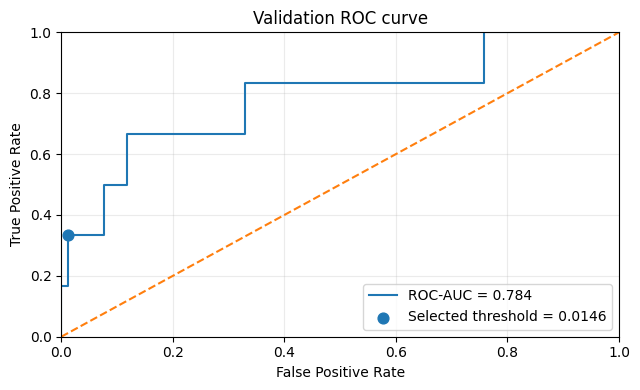

In [15]:
DECISION_THRESHOLD = 0.01460592

model.load_state_dict(torch.load(BEST_CHECKPOINT_PATH, map_location=DEVICE))
model.eval()

val_loss, _, val_labels, val_probs, val_stats = run_epoch(
    val_loader,
    train_mode=False
)

# Apply validation-selected threshold instead of argmax / 0.5
val_preds = [
    int(prob >= DECISION_THRESHOLD)
    for prob in val_probs
]

print(f"Validation loss: {val_loss:.4f}")
print(f"Decision threshold: {DECISION_THRESHOLD:.8f}")
print(f"PR-AUC:  {val_stats['pr_auc']:.4f}")
print(f"ROC-AUC: {val_stats['roc_auc']:.4f}")

print(
    classification_report(
        val_labels,
        val_preds,
        target_names=["general_guidance", "direct_solution"],
        zero_division=0
    )
)

cm = confusion_matrix(val_labels, val_preds, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()

print("Confusion matrix (rows=true, cols=pred):")
print(cm)

print(f"False Positive Rate: {fp / (fp + tn):.4f}")
print(f"Macro-F1: {f1_score(val_labels, val_preds, average='macro'):.4f}")

# ROC curve
fpr_curve, tpr_curve, thresholds_curve = roc_curve(val_labels, val_probs)

fig, ax = plt.subplots(figsize=(6.5, 4))

ax.plot(
    fpr_curve,
    tpr_curve,
    label=f"ROC-AUC = {val_stats['roc_auc']:.3f}"
)

ax.plot([0, 1], [0, 1], linestyle="--")

# Mark the selected operating point
selected_fpr = fp / (fp + tn)
selected_tpr = tp / (tp + fn)

ax.scatter(
    selected_fpr,
    selected_tpr,
    s=60,
    label=f"Selected threshold = {DECISION_THRESHOLD:.4f}"
)

ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_title("Validation ROC curve")
ax.grid(alpha=0.25)
ax.legend()

save_figure(fig, "roc_curve")

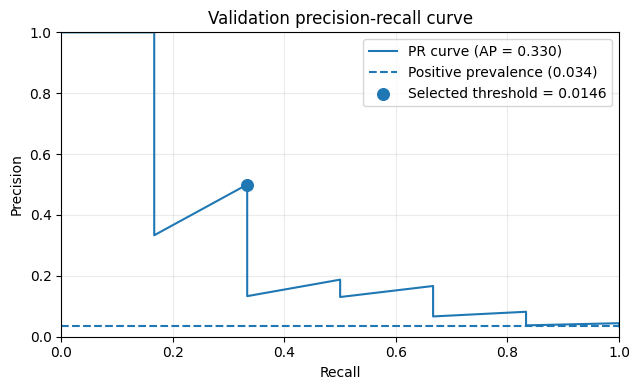

In [16]:
precision_curve, recall_curve, _ = precision_recall_curve(
    val_labels,
    val_probs
)

# Metrics at the selected decision threshold
threshold_preds = [
    int(prob >= DECISION_THRESHOLD)
    for prob in val_probs
]

selected_precision = precision_score(
    val_labels,
    threshold_preds,
    zero_division=0
)

selected_recall = recall_score(
    val_labels,
    threshold_preds,
    zero_division=0
)

fig, ax = plt.subplots(figsize=(6.5, 4))

ax.plot(
    recall_curve,
    precision_curve,
    label=f"PR curve (AP = {val_stats['pr_auc']:.3f})"
)

baseline = sum(val_labels) / len(val_labels)

ax.axhline(
    baseline,
    linestyle="--",
    label=f"Positive prevalence ({baseline:.3f})"
)

# Mark selected operating point
ax.scatter(
    selected_recall,
    selected_precision,
    s=70,
    zorder=5,
    label=f"Selected threshold = {DECISION_THRESHOLD:.4f}"
)

ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_title("Validation precision-recall curve")
ax.grid(alpha=0.25)
ax.legend()

save_figure(fig, "precision_recall_curve")

In [24]:
hub_config = {
    "setup_name": "ProximalityModernBERT (2-seg) Linear+GELU+Linear",
    "architectures": ["ProximalityClassifier"],
    "encoder": MODEL_NAME,
    "hidden_size": 768,
    "max_length": MAX_LENGTH,
    "head_hidden": HEAD_HIDDEN,
    "dropout_p": DROPOUT_P,
    "num_labels": 2,
    "label_map": {"0": "general_guidance", "1": "direct_solution"},
}
# This configuration is uploaded with the model in the final notebook cell.

Latency benchmark:   0%|          | 0/176 [00:00<?, ?it/s]

Mean:   35.04 ms
Median: 24.44 ms
P95:    75.46 ms
Max:    419.67 ms


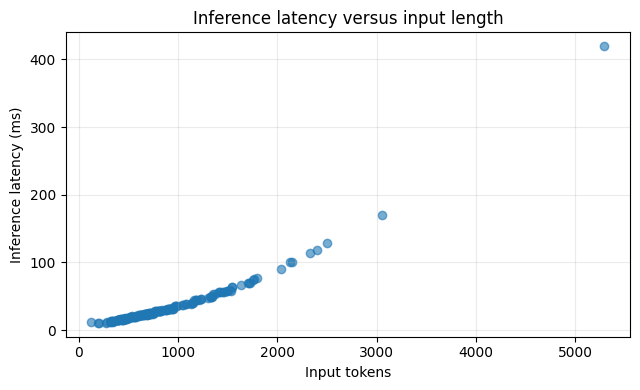

In [18]:
model.load_state_dict(torch.load(BEST_CHECKPOINT_PATH, map_location=DEVICE))
model.eval()

latency_rows = []

sample_batch = next(iter(val_loader))

with torch.no_grad():
    input_ids = sample_batch["input_ids"].to(DEVICE)
    attention_mask = sample_batch["attention_mask"].to(DEVICE)

    for _ in range(5):
        _ = model(input_ids, attention_mask)

if DEVICE.type == "cuda":
    torch.cuda.synchronize()

with torch.no_grad():
    for batch in tqdm(val_loader, desc="Latency benchmark"):
        input_ids = batch["input_ids"].to(DEVICE)
        attention_mask = batch["attention_mask"].to(DEVICE)

        token_count = int(attention_mask.sum().item())

        if DEVICE.type == "cuda":
            torch.cuda.synchronize()
            torch.cuda.reset_peak_memory_stats()

        start = time.perf_counter()

        _ = model(input_ids, attention_mask)

        if DEVICE.type == "cuda":
            torch.cuda.synchronize()

        latency_ms = (time.perf_counter() - start) * 1000

        latency_rows.append({
            "tokens": token_count,
            "latency_ms": latency_ms,
            "peak_vram_gib": (
                torch.cuda.max_memory_allocated() / 1024**3
                if DEVICE.type == "cuda" else float("nan")
            )
        })

latency_df = pd.DataFrame(latency_rows)

latency_df.to_csv(
    os.path.join(OUTPUT_DIR, "inference_latency.csv"),
    index=False
)

print(f"Mean:   {latency_df['latency_ms'].mean():.2f} ms")
print(f"Median: {latency_df['latency_ms'].median():.2f} ms")
print(f"P95:    {latency_df['latency_ms'].quantile(0.95):.2f} ms")
print(f"Max:    {latency_df['latency_ms'].max():.2f} ms")


fig, ax = plt.subplots(figsize=(6.5, 4))

ax.scatter(
    latency_df["tokens"],
    latency_df["latency_ms"],
    alpha=0.6
)

ax.set_xlabel("Input tokens")
ax.set_ylabel("Inference latency (ms)")
ax.set_title("Inference latency versus input length")
ax.grid(alpha=0.25)

save_figure(fig, "latency_vs_tokens")

In [19]:
test_ds = ProximalityDataset(test_df, tokenizer)

test_loader = DataLoader(
    test_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=data_collator
)

In [20]:
model.load_state_dict(torch.load(BEST_CHECKPOINT_PATH, map_location=DEVICE))
model.eval()

test_loss, _, test_labels, test_probs, test_stats = run_epoch(
    test_loader,
    train_mode=False
)

# Apply the frozen validation-selected threshold
test_preds = [
    int(prob >= DECISION_THRESHOLD)
    for prob in test_probs
]

print(f"Test loss: {test_loss:.4f}")
print(f"Decision threshold: {DECISION_THRESHOLD:.8f}")
print(f"PR-AUC:  {test_stats['pr_auc']:.4f}")
print(f"ROC-AUC: {test_stats['roc_auc']:.4f}")

print(
    classification_report(
        test_labels,
        test_preds,
        target_names=["general_guidance", "direct_solution"],
        zero_division=0
    )
)

cm = confusion_matrix(
    test_labels,
    test_preds,
    labels=[0, 1]
)

tn, fp, fn, tp = cm.ravel()

fpr = fp / (fp + tn) if (fp + tn) > 0 else float("nan")

print(
    "Confusion matrix (rows=true, cols=pred), "
    "order=[general_guidance, direct_solution]:"
)
print(cm)

print(
    f"False Positive Rate "
    f"(general guidance wrongly flagged direct_solution): "
    f"{fpr:.4f}"
)

print(
    f"Macro-F1: "
    f"{f1_score(test_labels, test_preds, average='macro', zero_division=0):.4f}"
)

print(
    f"Direct-solution precision: "
    f"{precision_score(test_labels, test_preds, zero_division=0):.4f}"
)

print(
    f"Direct-solution recall: "
    f"{recall_score(test_labels, test_preds, zero_division=0):.4f}"
)

Validation:   0%|          | 0/46 [00:00<?, ?it/s]

Test loss: 1.5162
Decision threshold: 0.01460592
PR-AUC:  0.5024
ROC-AUC: 0.7500
                  precision    recall  f1-score   support

general_guidance       0.92      0.29      0.44        42
 direct_solution       0.09      0.75      0.16         4

        accuracy                           0.33        46
       macro avg       0.51      0.52      0.30        46
    weighted avg       0.85      0.33      0.41        46

Confusion matrix (rows=true, cols=pred), order=[general_guidance, direct_solution]:
[[12 30]
 [ 1  3]]
False Positive Rate (general guidance wrongly flagged direct_solution): 0.7143
Macro-F1: 0.2993
Direct-solution precision: 0.0909
Direct-solution recall: 0.7500


In [25]:
import json
import os

EXPORT_DIR = "../solution_proximality_modernbert/hf_export"

model.load_state_dict(
    torch.load(BEST_CHECKPOINT_PATH, map_location=DEVICE)
)
model.eval()

model.save_pretrained(
    EXPORT_DIR,
    config=hub_config
)

tokenizer.save_pretrained(EXPORT_DIR)

inference_config = {
    "decision_threshold": DECISION_THRESHOLD,
    "positive_class_id": 1,
    "positive_label": "direct_solution",
    "negative_label": "general_guidance",
    "score_type": "softmax_probability",
    "checkpoint_selection_metric": "validation_pr_auc",
    "threshold_selection_metric": "validation_macro_f1",
}

with open(
    os.path.join(EXPORT_DIR, "inference_config.json"),
    "w"
) as f:
    json.dump(inference_config, f, indent=2)

print(f"Saved Hugging Face export to {EXPORT_DIR}")

Saved Hugging Face export to ../solution_proximality_modernbert/hf_export


In [26]:
loaded_tokenizer = AutoTokenizer.from_pretrained(EXPORT_DIR)

loaded_model = ProximalityClassifier.from_pretrained(
    EXPORT_DIR
).to(DEVICE)

loaded_model.eval()

with open(
    os.path.join(EXPORT_DIR, "inference_config.json")
) as f:
    inference_config = json.load(f)

DECISION_THRESHOLD = inference_config["decision_threshold"]

print("Decision threshold:", DECISION_THRESHOLD)

Loading weights:   0%|          | 0/134 [00:00<?, ?it/s]

[transformers] ModernBertModel LOAD REPORT from: answerdotai/ModernBERT-base
Key               | Status     |  | 
------------------+------------+--+-
decoder.bias      | UNEXPECTED |  | 
head.dense.weight | UNEXPECTED |  | 
head.norm.weight  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights from local directory
Decision threshold: 0.01460592


In [27]:
batch = next(iter(val_loader))

input_ids = batch["input_ids"].to(DEVICE)
attention_mask = batch["attention_mask"].to(DEVICE)

model.eval()
loaded_model.eval()

with torch.no_grad():
    original_logits = model(input_ids, attention_mask)
    loaded_logits = loaded_model(input_ids, attention_mask)

print(
    "Max absolute difference:",
    (original_logits - loaded_logits).abs().max().item()
)

Max absolute difference: 0.0


In [ ]:
# Sample Inference Code

import json
import os
import torch
from transformers import AutoTokenizer

EXPORT_DIR = "../solution_proximality_modernbert/hf_export"

# Load tokenizer + model
tokenizer = AutoTokenizer.from_pretrained(EXPORT_DIR)

model = ProximalityClassifier.from_pretrained(
    EXPORT_DIR
).to(DEVICE)

model.eval()

# Load calibrated inference metadata
with open(os.path.join(EXPORT_DIR, "inference_config.json")) as f:
    inference_config = json.load(f)

DECISION_THRESHOLD = inference_config["decision_threshold"]


def predict_solution_proximity(
    assignment_context,
    previous_conversation,
    user_query,
    assistant_response
):
    text = (
        f"[ASSIGNMENT]\n{assignment_context}\n\n"
        f"[PREVIOUS CONVERSATION]\n{previous_conversation}\n\n"
        f"[USER QUERY]\n{user_query}\n\n"
        f"[ASSISTANT RESPONSE]\n{assistant_response}"
    )

    inputs = tokenizer(
        text,
        truncation=True,
        max_length=MAX_LENGTH,
        return_tensors="pt"
    )

    input_ids = inputs["input_ids"].to(DEVICE)
    attention_mask = inputs["attention_mask"].to(DEVICE)

    with torch.no_grad():
        logits = model(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        prob_direct_solution = torch.softmax(
            logits,
            dim=-1
        )[0, 1].item()

    predicted_label = (
        "direct_solution"
        if prob_direct_solution >= DECISION_THRESHOLD
        else "general_guidance"
    )

    return {
        "label": predicted_label,
        "prob_direct_solution": prob_direct_solution,
        "threshold": DECISION_THRESHOLD
    }

In [ ]:
# Publish the best checkpoint, custom-head architecture metadata, and tokenizer.
model.load_state_dict(torch.load(BEST_CHECKPOINT_PATH, map_location=DEVICE))
model.eval()
model.push_to_hub(
    HF_REPO_ID,
    token=HF_WRITE_TOKEN,
    config=hub_config,
    commit_message=f"Upload best solution-proximality classifier (val macro F1: {best_val_f1:.4f})",
)
tokenizer.push_to_hub(HF_REPO_ID, token=HF_WRITE_TOKEN, commit_message="Upload tokenizer")
print(f"Uploaded model architecture metadata, backbone and classifier weights, and tokenizer to https://huggingface.co/{HF_REPO_ID}")

In [ ]:
# Run this after the final upload cell (or to use a previously uploaded version).
hub_tokenizer = AutoTokenizer.from_pretrained(HF_REPO_ID, token=HF_READ_TOKEN)
hub_model = ProximalityClassifier.from_pretrained(HF_REPO_ID, token=HF_READ_TOKEN).to(DEVICE)
hub_model.eval()

assignment_context = "Your assignment context here"
previous_conversation = "Previous conversation here"
user_query = "User query here"
assistant_response = "Assistant response here"

text = (
    f"[ASSIGNMENT]\n{assignment_context.strip()}\n\n"
    f"[PREVIOUS CONVERSATION]\n{previous_conversation.strip()}\n\n"
    f"[CURRENT USER QUERY]\n{user_query.strip()}\n\n"
    f"[CURRENT ASSISTANT RESPONSE]\n{assistant_response.strip()}"
)
inputs = hub_tokenizer(text, return_tensors="pt", truncation=True, max_length=MAX_LENGTH).to(DEVICE)
with torch.no_grad():
    predicted_id = hub_model(**inputs).argmax(dim=-1).item()

labels = {0: "general_guidance", 1: "direct_solution"}
print(f"Prediction: {labels[predicted_id]}")